# [핸즈온 머신러닝] Chapter 5 – 결정 트리 (Decision Trees)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/jsmak/handson-mlp-study/blob/main/ch05/05_decision_trees_kr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>
<br clear="left"/>

> **📚 출처 및 라이선스**
>
> - **원본 노트북**: [rickiepark/handson-mlp](https://github.com/rickiepark/handson-mlp) – [`05_decision_trees.ipynb`](https://github.com/rickiepark/handson-mlp/blob/main/05_decision_trees.ipynb) (박해선 님, 『핸즈온 머신러닝 with 사이킷런, 파이토치』 한빛미디어, 2026 예제 코드)
> - **원저작**: [ageron/handson-mlp](https://github.com/ageron/handson-mlp) (Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch*, O'Reilly)
> - **라이선스**: 원본 코드는 [Apache License 2.0](https://github.com/rickiepark/handson-mlp/blob/main/LICENSE)을 따릅니다.
> - **변경 사항**: 개인 학습(인프런 챌린지 복습) 목적으로 원본 노트북을 바탕으로 한국어 설명·주석을 추가하고, 셀 구성을 책의 절 번호에 맞춰 재정리했습니다. 책 본문은 포함하지 않습니다.

분류·회귀에 모두 쓰이는 **결정 트리**를 붓꽃 데이터셋으로 훈련·시각화하고, CART 알고리즘, 불순도, 규제, 회귀 트리, 그리고 결정 트리의 한계(축 방향 민감성, 높은 분산)까지 살펴봅니다.

| 절 | 내용 | 주요 코드 |
|---|---|---|
| 5.1 | 결정 트리 학습과 시각화 | `DecisionTreeClassifier`, `export_graphviz` |
| 5.2 | 예측 (노드 속성, 지니 불순도, 결정 경계) | `tree_.threshold` |
| 5.3 | 클래스 확률 추정 | `predict_proba` |
| 5.4 | CART 훈련 알고리즘 | – |
| 5.5 | 계산 복잡도 | – |
| 5.6 | 지니 불순도 또는 엔트로피? | 직접 계산 |
| 5.7 | 규제 하이퍼파라미터 | `min_samples_leaf`, `make_moons` |
| 5.8 | 회귀 | `DecisionTreeRegressor` |
| 5.9 | 축 방향에 대한 민감성 | `PCA`, `StandardScaler` |
| 5.10 | 결정 트리의 분산 문제 | `random_state` |

## **5.1 결정 트리 학습과 시각화**

붓꽃 데이터셋의 꽃잎 길이·너비 두 특성으로 `DecisionTreeClassifier`(최대 깊이 2)를 훈련하고, `export_graphviz()`로 트리를 그립니다.

꽃잎 특성 두 개로 깊이 2인 결정 트리를 훈련하고 Graphviz로 시각화합니다.

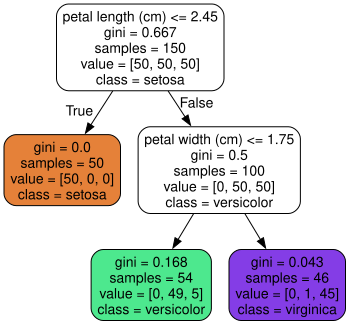

In [1]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import graphviz

iris = load_iris(as_frame=True)
feature_names = ["petal length (cm)", "petal width (cm)"]
X_iris = iris.data[feature_names].values
y_iris = iris.target

tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X_iris, y_iris)

# 트리를 DOT 형식 문자열로 내보낸 뒤 graphviz로 렌더링
dot_data = export_graphviz(tree_clf, feature_names=feature_names,
                           class_names=iris.target_names, rounded=True, filled=True)
graphviz.Source(dot_data)

## **5.2 예측**

- **루트 노드(root node)**: 깊이 0. 꽃잎 길이 ≤ 2.45cm인지 검사합니다. 참이면 왼쪽 **리프 노드(leaf node)** → Setosa.
- 거짓이면 오른쪽 **분할 노드(split node)** 로 가서 꽃잎 너비 ≤ 1.75cm인지 검사 → 참이면 Versicolor, 거짓이면 Virginica.

노드 속성:

| 속성 | 의미 | 예 |
|---|---|---|
| `samples` | 노드에 도달한 훈련 샘플 수 | 깊이 2 왼쪽 노드: 54 |
| `value` | 노드의 클래스별 훈련 샘플 수 | 맨 오른쪽 아래 노드: [0, 1, 45] |
| `gini` | 지니 불순도 (0이면 순수 노드) | 깊이 1 왼쪽 노드: 0 |

$$G_i = 1 - \sum_{k=1}^{n} p_{i,k}^2$$

예) 깊이 2 왼쪽 노드: $1 - (0/54)^2 - (49/54)^2 - (5/54)^2 \approx 0.168$

> 💡 결정 트리는 특성 스케일 조정이나 원점 맞추기 같은 전처리가 거의 필요 없습니다.

깊이 2 트리의 결정 경계를 그리고, 깊이 3 트리가 추가로 만드는 경계(점선)도 함께 표시합니다.

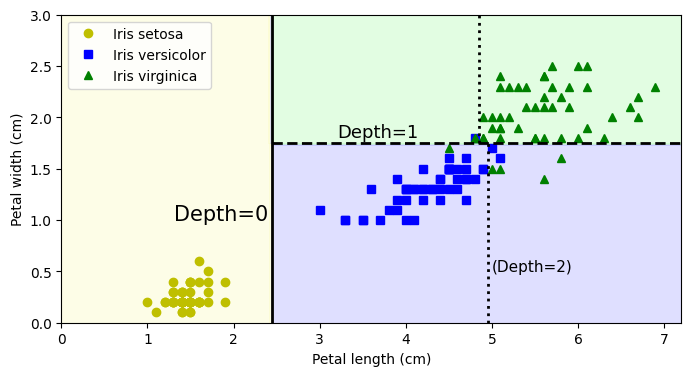

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
plt.figure(figsize=(8, 4))

# 격자점 전체를 예측해 영역별 클래스를 색칠
lengths, widths = np.meshgrid(np.linspace(0, 7.2, 100), np.linspace(0, 3, 100))
X_iris_all = np.c_[lengths.ravel(), widths.ravel()]
y_pred = tree_clf.predict(X_iris_all).reshape(lengths.shape)
plt.contourf(lengths, widths, y_pred, alpha=0.3, cmap=custom_cmap)
for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris[:, 0][y_iris == idx], X_iris[:, 1][y_iris == idx], style, label=f"Iris {name}")

# 깊이 3 트리의 분할 임곗값 (노드 0, 2, 3, 6)
tree_clf_deeper = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf_deeper.fit(X_iris, y_iris)
th0, th1, th2a, th2b = tree_clf_deeper.tree_.threshold[[0, 2, 3, 6]]
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.plot([th0, th0], [0, 3], "k-", linewidth=2)         # 깊이 0: 꽃잎 길이 = 2.45
plt.plot([th0, 7.2], [th1, th1], "k--", linewidth=2)    # 깊이 1: 꽃잎 너비 = 1.75
plt.plot([th2a, th2a], [0, th1], "k:", linewidth=2)     # 깊이 2 (max_depth=3일 때)
plt.plot([th2b, th2b], [th1, 3], "k:", linewidth=2)
plt.text(th0 - 0.05, 1.0, "Depth=0", horizontalalignment="right", fontsize=15)
plt.text(3.2, th1 + 0.02, "Depth=1", verticalalignment="bottom", fontsize=13)
plt.text(th2a + 0.05, 0.5, "(Depth=2)", fontsize=11)
plt.axis([0, 7.2, 0, 3])
plt.legend()
plt.show()

→ 굵은 실선(깊이 0)의 왼쪽은 Setosa만 있는 순수 노드라 더 나누지 않고, 오른쪽은 파선(깊이 1)에서 한 번 더 나뉩니다. 점선은 `max_depth=3`일 때 추가되는 경계입니다.

> 💡 `tree_clf.tree_` 속성으로 트리 구조 전체(임곗값, 자식 노드, 샘플 수 등)에 접근할 수 있습니다. 자세한 내용은 `help(tree_clf.tree_)`를 참고하세요.

결정 트리는 예측 과정을 사람이 직접 따라갈 수 있는 **화이트박스(white box)** 모델입니다. 반면 랜덤 포레스트·신경망은 왜 그런 예측을 했는지 설명하기 어려운 **블랙박스(black box)** 모델입니다.

## **5.3 클래스 확률 추정**

샘플이 도달한 리프 노드에서 클래스 $k$인 훈련 샘플의 비율을 확률로 반환합니다.

꽃잎 길이 5cm, 너비 1.5cm인 꽃의 클래스 확률과 예측 클래스를 구합니다.

In [3]:
print(tree_clf.predict_proba([[5, 1.5]]).round(3))  # [[0.    0.907 0.093]] → 0/54, 49/54, 5/54
print(tree_clf.predict([[5, 1.5]]))  # [1] → Versicolor

[[0.    0.907 0.093]]
[1]


→ 깊이 2 왼쪽 리프 노드에 도달하므로 Versicolor 90.7%, Virginica 9.3%입니다. 같은 사각형 영역 안이면(예: 길이 6cm, 너비 1.5cm) 확률도 같습니다.

## **5.4 CART 훈련 알고리즘**

사이킷런은 **CART(Classification And Regression Tree)** 알고리즘으로 이진 트리를 만듭니다. 하나의 특성 $k$와 임곗값 $t_k$로 훈련 세트를 둘로 나누되, 크기로 가중치를 준 불순도가 가장 작아지는 $(k, t_k)$를 찾습니다.

$$J(k, t_k) = \frac{m_{\text{left}}}{m} G_{\text{left}} + \frac{m_{\text{right}}}{m} G_{\text{right}}$$

- $G_{\text{left/right}}$: 왼쪽/오른쪽 서브셋의 불순도, $m_{\text{left/right}}$: 왼쪽/오른쪽 서브셋의 샘플 수
- `max_depth`에 도달하거나 불순도를 줄이는 분할을 찾지 못하면 멈춥니다. (`min_samples_split`, `min_samples_leaf`, `max_leaf_nodes` 등도 중지 조건)

> ⚠ CART는 **탐욕 알고리즘(greedy algorithm)** 이라 각 단계에서 최선의 분할만 고르고 최적의 트리를 보장하지 않습니다. 최적의 트리를 찾는 문제는 NP-완전 문제($O(\exp(m))$)입니다.

## **5.5 계산 복잡도**

| 구분 | 복잡도 | 설명 |
|---|---|---|
| 예측 | $O(\log_2(m))$ | 루트에서 리프까지 약 $\log_2(m)$개 노드만 거침. 특성 수와 무관 |
| 훈련 | $O(n \times m \log_2(m))$ | 각 노드에서 모든 샘플의 모든 특성을 비교 |

## **5.6 지니 불순도 또는 엔트로피?**

`criterion="entropy"`로 지정하면 지니 불순도 대신 **엔트로피(entropy)** 를 사용합니다.

$$H_i = -\sum_{\substack{k=1 \\ p_{i,k} \neq 0}}^{n} p_{i,k} \log_2(p_{i,k})$$

깊이 2 왼쪽 노드(Setosa 0, Versicolor 49, Virginica 5)의 지니 불순도와 엔트로피를 직접 계산합니다.

In [4]:
p = np.array([0, 49, 5]) / 54  # 깊이 2 왼쪽 노드의 클래스 비율

gini = 1 - (p ** 2).sum()
entropy = -(p[p > 0] * np.log2(p[p > 0])).sum()  # p=0인 클래스는 제외
print(f"지니 불순도: {gini:.3f}")  # 0.168
print(f"엔트로피: {entropy:.3f}")  # 0.445

지니 불순도: 0.168
엔트로피: 0.445


→ 둘 다 비슷한 트리를 만듭니다. 지니 불순도가 계산이 조금 더 빨라 기본값이며, 지니는 가장 빈도 높은 클래스를 한쪽 가지로 고립시키는 경향이, 엔트로피는 조금 더 균형 잡힌 트리를 만드는 경향이 있습니다.

## **5.7 규제 하이퍼파라미터**

결정 트리는 훈련 전에 파라미터 수가 정해지지 않는 **비파라미터 모델(nonparametric model)** 이라 제한하지 않으면 과대적합되기 쉽습니다.

| 하이퍼파라미터 | 의미 | 규제하려면 |
|---|---|---|
| `max_depth` | 트리의 최대 깊이 (기본값 `None`: 제한 없음) | 감소 |
| `max_features` | 각 노드에서 분할에 사용할 특성의 최대 수 | 감소 |
| `max_leaf_nodes` | 리프 노드의 최대 수 | 감소 |
| `min_samples_split` | 분할되기 위해 노드가 가져야 하는 최소 샘플 수 | 증가 |
| `min_samples_leaf` | 리프 노드가 가져야 하는 최소 샘플 수 | 증가 |
| `min_weight_fraction_leaf` | `min_samples_leaf`와 같지만 가중치 합에 대한 비율 | 증가 |
| `min_impurity_decrease` | 분할로 얻어야 하는 최소 불순도 감소량 | 증가 |
| `ccp_alpha` | 최소 비용 복잡도 가지치기 강도 (기본값 0: 가지치기 안 함) | 증가 |

moons 데이터셋으로 규제가 없는 트리와 `min_samples_leaf=5`인 트리를 비교합니다.

잡음이 있는 moons 데이터셋(샘플 150개)으로 규제 없는 트리와 `min_samples_leaf=5` 트리를 훈련합니다.

In [5]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)

tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
tree_clf1.fit(X_moons, y_moons)
tree_clf2.fit(X_moons, y_moons);  # 세미콜론: 모델 출력 생략

이진 분류기의 결정 경계를 그리는 함수입니다. (5.9절에서도 다시 사용)

In [6]:
def plot_decision_boundary(clf, X, y, axes, cmap):
    x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 100), np.linspace(axes[2], axes[3], 100))
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)

    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=cmap)    # 예측 영역 색칠
    plt.contour(x1, x2, y_pred, cmap="Greys", alpha=0.8)  # 결정 경계선
    colors = {"Wistia": ["#78785c", "#c47b27"], "Pastel1": ["red", "blue"]}
    markers = ("o", "^")
    for idx in (0, 1):
        plt.plot(X[:, 0][y == idx], X[:, 1][y == idx], color=colors[cmap][idx],
                 marker=markers[idx], linestyle="none")
    plt.axis(axes)
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$", rotation=0)

두 트리의 결정 경계를 나란히 비교합니다.

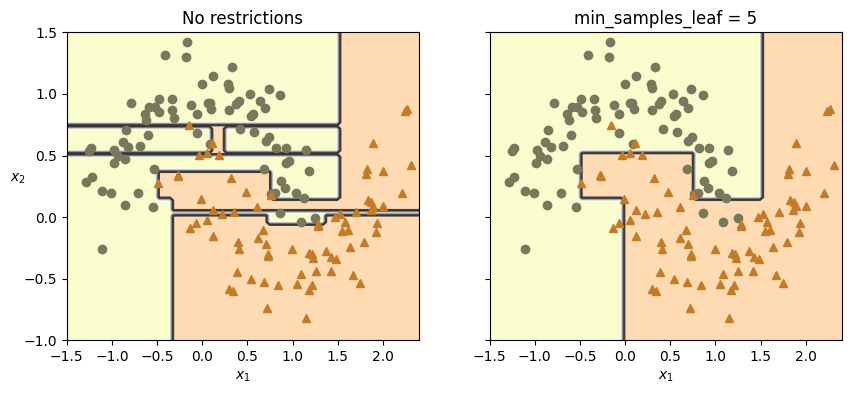

In [7]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf1, X_moons, y_moons, axes=[-1.5, 2.4, -1, 1.5], cmap="Wistia")
plt.title("No restrictions")
plt.sca(axes[1])
plot_decision_boundary(tree_clf2, X_moons, y_moons, axes=[-1.5, 2.4, -1, 1.5], cmap="Wistia")
plt.title(f"min_samples_leaf = {tree_clf2.min_samples_leaf}")
plt.ylabel("")
plt.show()

다른 랜덤 시드로 만든 테스트 세트(샘플 1,000개)에서 두 트리의 정확도를 비교합니다.

In [8]:
X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2, random_state=43)
print(tree_clf1.score(X_moons_test, y_moons_test)) # 0.898
print(tree_clf2.score(X_moons_test, y_moons_test)) # 0.92

0.898
0.92


→ 규제한 오른쪽 트리(0.92)가 규제 없는 트리(0.898)보다 테스트 정확도가 높아 일반화가 더 잘 됩니다.

## **5.8 회귀**

`DecisionTreeRegressor`는 각 노드에서 클래스 대신 **값**을 예측합니다. 리프 노드의 예측값은 그 노드에 속한 훈련 샘플의 **평균 타깃값**입니다.

잡음이 섞인 2차 함수 데이터셋으로 깊이 2인 회귀 트리를 훈련하고 시각화합니다.

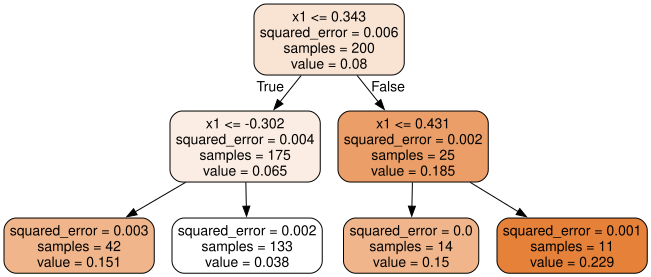

In [9]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(seed=42)
X_quad = rng.random((200, 1)) - 0.5  # 랜덤한 입력 특성 하나
y_quad = X_quad ** 2 + 0.025 * rng.standard_normal((200, 1))

tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(X_quad, y_quad)
dot_data = export_graphviz(tree_reg, feature_names=["x1"], rounded=True, filled=True)
graphviz.Source(dot_data)

→ 예) $x_1 = 0.2$: 루트($x_1 \le 0.343$, 참) → 왼쪽($x_1 \le -0.302$, 거짓) → 오른쪽 리프 노드. 이 노드에 있는 훈련 샘플 133개의 평균인 `value=0.038`을 예측합니다.

깊이 2(왼쪽)와 깊이 3(오른쪽) 회귀 트리의 예측을 비교합니다. 각 영역의 예측값은 그 영역 타깃값의 평균입니다.

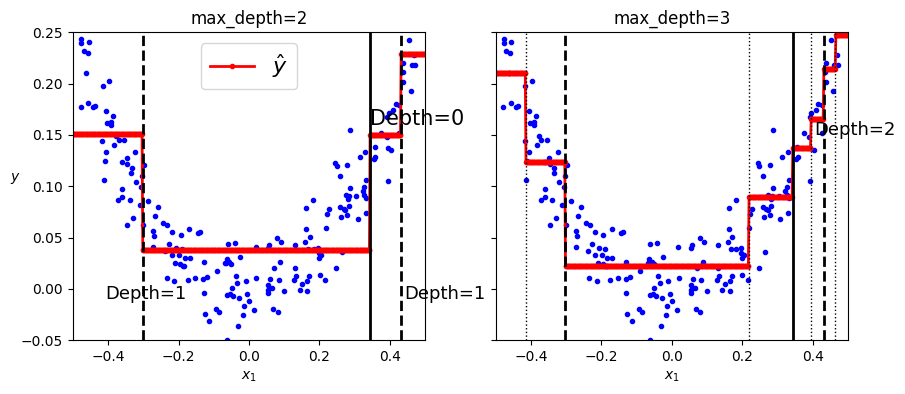

In [10]:
def plot_regression_predictions(tree_reg, X, y, axes=[-0.5, 0.5, -0.05, 0.25]):
    x1 = np.linspace(axes[0], axes[1], 500).reshape(-1, 1)
    y_pred = tree_reg.predict(x1)
    plt.axis(axes)
    plt.xlabel("$x_1$")
    plt.plot(X, y, "b.")
    plt.plot(x1, y_pred, "r.-", linewidth=2, label=r"$\hat{y}$")

tree_reg2 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_reg2.fit(X_quad, y_quad)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_regression_predictions(tree_reg, X_quad, y_quad)

th0, th1a, th1b = tree_reg.tree_.threshold[[0, 1, 4]]
for split, style in ((th0, "k-"), (th1a, "k--"), (th1b, "k--")):
    plt.plot([split, split], [-0.05, 0.25], style, linewidth=2)
plt.text(th0, 0.16, "Depth=0", fontsize=15)
plt.text(th1a + 0.01, -0.01, "Depth=1", horizontalalignment="center", fontsize=13)
plt.text(th1b + 0.01, -0.01, "Depth=1", fontsize=13)
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper center", fontsize=16)
plt.title("max_depth=2")

plt.sca(axes[1])
th2s = tree_reg2.tree_.threshold[[2, 5, 9, 12]]
plot_regression_predictions(tree_reg2, X_quad, y_quad)
for split, style in ((th0, "k-"), (th1a, "k--"), (th1b, "k--")):
    plt.plot([split, split], [-0.05, 0.25], style, linewidth=2)
for split in th2s:
    plt.plot([split, split], [-0.05, 0.25], "k:", linewidth=1)
plt.text(th2s[2] + 0.01, 0.15, "Depth=2", fontsize=13)
plt.title("max_depth=3")

plt.show()

회귀에서 CART는 불순도 대신 **MSE**를 최소화하도록 분할합니다.

$$J(k, t_k) = \frac{m_{\text{left}}}{m} \text{MSE}_{\text{left}} + \frac{m_{\text{right}}}{m} \text{MSE}_{\text{right}}$$

$$\text{MSE}_{\text{node}} = \frac{1}{m_{\text{node}}} \sum_{i \in \text{node}} \left(\hat{y}_{\text{node}} - y^{(i)}\right)^2, \quad \hat{y}_{\text{node}} = \frac{1}{m_{\text{node}}} \sum_{i \in \text{node}} y^{(i)}$$

규제 없는 회귀 트리와 `min_samples_leaf=10` 회귀 트리의 예측을 비교합니다.

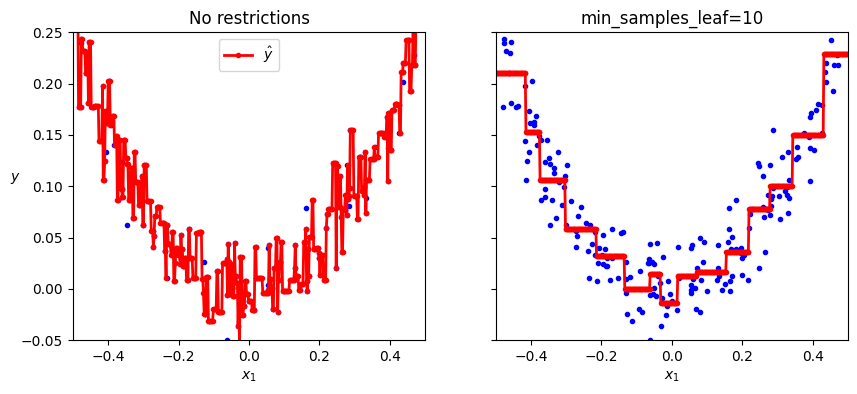

In [11]:
tree_reg1 = DecisionTreeRegressor(random_state=42)
tree_reg2 = DecisionTreeRegressor(random_state=42, min_samples_leaf=10)
tree_reg1.fit(X_quad, y_quad)
tree_reg2.fit(X_quad, y_quad)

x1 = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)
y_pred1 = tree_reg1.predict(x1)
y_pred2 = tree_reg2.predict(x1)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plt.plot(X_quad, y_quad, "b.")
plt.plot(x1, y_pred1, "r.-", linewidth=2, label=r"$\hat{y}$")
plt.axis([-0.5, 0.5, -0.05, 0.25])
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper center")
plt.title("No restrictions")

plt.sca(axes[1])
plt.plot(X_quad, y_quad, "b.")
plt.plot(x1, y_pred2, "r.-", linewidth=2, label=r"$\hat{y}$")
plt.axis([-0.5, 0.5, -0.05, 0.25])
plt.xlabel("$x_1$")
plt.title(f"min_samples_leaf={tree_reg2.min_samples_leaf}")
plt.show()

→ 규제가 없으면 훈련 세트에 크게 과대적합되고, `min_samples_leaf=10`이면 훨씬 그럴듯한 모델이 됩니다.

## **5.9 축 방향에 대한 민감성**

결정 트리의 분할은 항상 축에 수직이라 결정 경계가 계단 모양이 되고, 데이터의 방향에 민감합니다.

선형으로 구분되는 데이터셋과 이를 45° 회전한 데이터셋에 각각 결정 트리를 훈련해 결정 경계를 비교합니다.

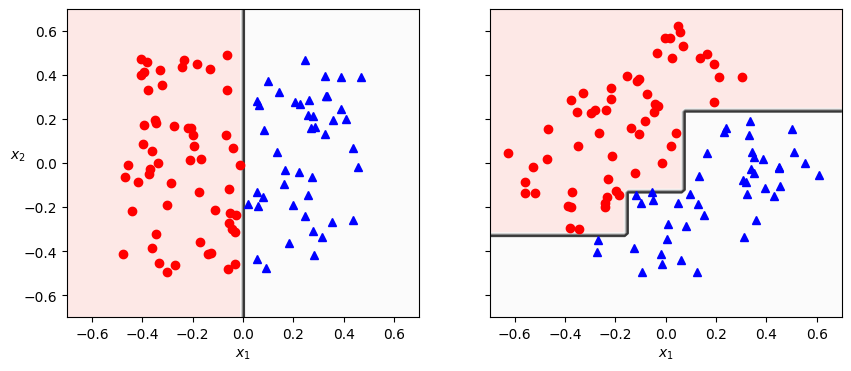

In [12]:
rng = np.random.default_rng(seed=42)
X_square = rng.random((100, 2)) - 0.5
y_square = (X_square[:, 0] > 0).astype(np.int64)

angle = np.pi / 4  # 45도
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
X_rotated_square = X_square.dot(rotation_matrix)

tree_clf_square = DecisionTreeClassifier(random_state=42)
tree_clf_square.fit(X_square, y_square)
tree_clf_rotated_square = DecisionTreeClassifier(random_state=42)
tree_clf_rotated_square.fit(X_rotated_square, y_square)

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(axes[0])
plot_decision_boundary(tree_clf_square, X_square, y_square, axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.sca(axes[1])
plot_decision_boundary(tree_clf_rotated_square, X_rotated_square, y_square, axes=[-0.7, 0.7, -0.7, 0.7], cmap="Pastel1")
plt.ylabel("")
plt.show()

→ 둘 다 훈련 세트를 완벽히 학습했지만, 회전한 오른쪽 트리는 경계가 구불구불해 일반화가 잘 안 될 것입니다.

해결 방법 하나는 스케일을 조정한 뒤 **주성분 분석(PCA)** 으로 데이터를 회전하는 것입니다. (PCA는 7장에서 자세히 다룹니다.)

`StandardScaler` + `PCA` 파이프라인으로 붓꽃 데이터를 회전한 뒤 깊이 2 트리를 훈련해 결정 경계를 그립니다.

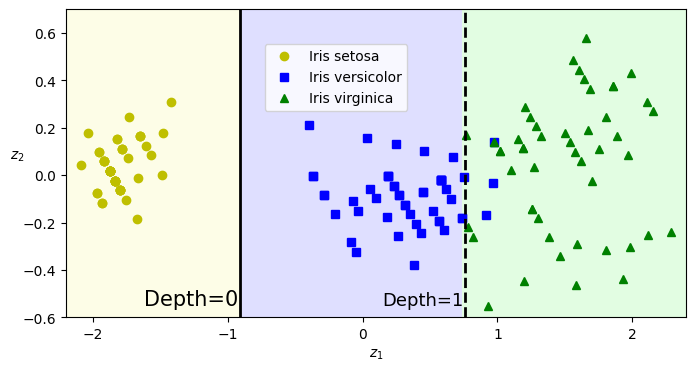

In [13]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pca_pipeline = make_pipeline(StandardScaler(), PCA())
X_iris_rotated = pca_pipeline.fit_transform(X_iris)
tree_clf_pca = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf_pca.fit(X_iris_rotated, y_iris)

plt.figure(figsize=(8, 4))
axes = [-2.2, 2.4, -0.6, 0.7]
z0s, z1s = np.meshgrid(np.linspace(axes[0], axes[1], 100), np.linspace(axes[2], axes[3], 100))
X_iris_pca_all = np.c_[z0s.ravel(), z1s.ravel()]
y_pred = tree_clf_pca.predict(X_iris_pca_all).reshape(z0s.shape)

plt.contourf(z0s, z1s, y_pred, alpha=0.3, cmap=custom_cmap)
for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris_rotated[:, 0][y_iris == idx], X_iris_rotated[:, 1][y_iris == idx], style, label=f"Iris {name}")

plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
th1, th2 = tree_clf_pca.tree_.threshold[[0, 2]]
plt.plot([th1, th1], axes[2:], "k-", linewidth=2)
plt.plot([th2, th2], axes[2:], "k--", linewidth=2)
plt.text(th1 - 0.01, axes[2] + 0.05, "Depth=0", horizontalalignment="right", fontsize=15)
plt.text(th2 - 0.01, axes[2] + 0.05, "Depth=1", horizontalalignment="right", fontsize=13)
plt.axis(axes)
plt.legend(loc=(0.32, 0.67))
plt.show()

→ 회전 후에는 꽃잎 길이·너비의 선형 함수인 $z_1$ 특성 하나만으로 데이터셋을 잘 나눌 수 있습니다.

> 💡 `DecisionTreeClassifier`와 `DecisionTreeRegressor`는 누락된 값(NaN)을 지원하므로 `SimpleImputer`로 채우지 않아도 됩니다.

## **5.10 결정 트리의 분산 문제**

결정 트리는 **분산이 큽니다**. 하이퍼파라미터나 데이터를 조금만 바꿔도 매우 다른 모델이 만들어집니다. 사이킷런의 훈련 알고리즘은 확률적이므로 같은 데이터라도 `random_state`가 다르면 다른 트리가 나올 수 있습니다.

같은 데이터에서 `random_state`만 40으로 바꿔 깊이 2 트리를 다시 훈련하고 결정 경계를 그립니다.

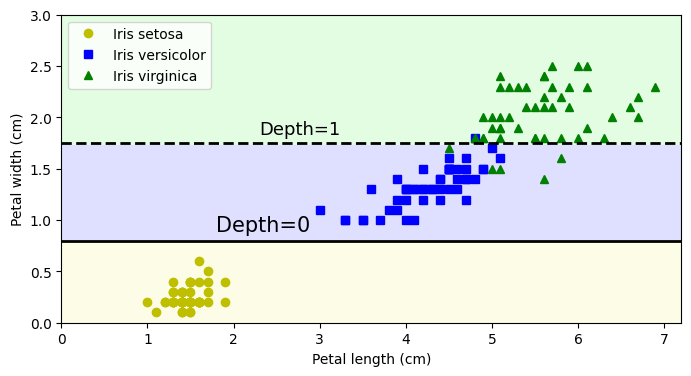

In [14]:
tree_clf_tweaked = DecisionTreeClassifier(max_depth=2, random_state=40)
tree_clf_tweaked.fit(X_iris, y_iris)

plt.figure(figsize=(8, 4))
y_pred = tree_clf_tweaked.predict(X_iris_all).reshape(lengths.shape)
plt.contourf(lengths, widths, y_pred, alpha=0.3, cmap=custom_cmap)

for idx, (name, style) in enumerate(zip(iris.target_names, ("yo", "bs", "g^"))):
    plt.plot(X_iris[:, 0][y_iris == idx], X_iris[:, 1][y_iris == idx], style, label=f"Iris {name}")

th0, th1 = tree_clf_tweaked.tree_.threshold[[0, 2]]
plt.plot([0, 7.2], [th0, th0], "k-", linewidth=2)
plt.plot([0, 7.2], [th1, th1], "k--", linewidth=2)
plt.text(1.8, th0 + 0.05, "Depth=0", verticalalignment="bottom", fontsize=15)
plt.text(2.3, th1 + 0.05, "Depth=1", verticalalignment="bottom", fontsize=13)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.axis([0, 7.2, 0, 3])
plt.legend()
plt.show()

→ 앞의 트리(꽃잎 길이 2.45에서 먼저 분할)와 달리 꽃잎 너비 0.8, 1.75에서 수평으로 분할하는 전혀 다른 트리가 만들어졌습니다.

여러 결정 트리의 예측을 평균하면 분산을 크게 줄일 수 있습니다. 이런 결정 트리의 앙상블이 6장에서 다룰 **랜덤 포레스트**입니다.